In [55]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [56]:
import numpy as np
from pygraphon.graphons import Graphon
from pygraphon.graphons import StepGraphon
from pygraphon.estimators import SmoothNetHist
from pygraphon.estimators import HistogramEstimator

from utils_generators import AssociativeFullyRandom
from pygraphon.norm import MseProbaEdge, MaeProbaEdge, AUCEdge, AUPRCEdge
import matplotlib.pyplot as plt
from pygraphon.plots.plot_matrices import spy


# Initialisation

In [57]:
n = 200
k = 2
theta_intra_min, theta_intra_max = 0.5, 0.7
theta_inter_min, theta_inter_max = 0.1, 0.4
theta = AssociativeFullyRandom(
                    K=k,
                    min_inside_classes=theta_intra_min,
                    max_inside_classes=theta_intra_max,
                    min_outside_classes=theta_inter_min,
                    max_outside_classes=theta_inter_max,
                )
print(theta.Theta)
graphon = StepGraphon(theta.Theta, bandwidthHist=1 / k)
adjacency_matrix = graphon.draw(n=n, exchangeable=False)

[[0.69622884 0.28521397]
 [0.28521397 0.51257652]]


# Olhede fit

In [58]:
est = SmoothNetHist()
first_hist_olhede = est._first_approximate_graphon_from_adjacency(adjacencyMatrix= adjacency_matrix)

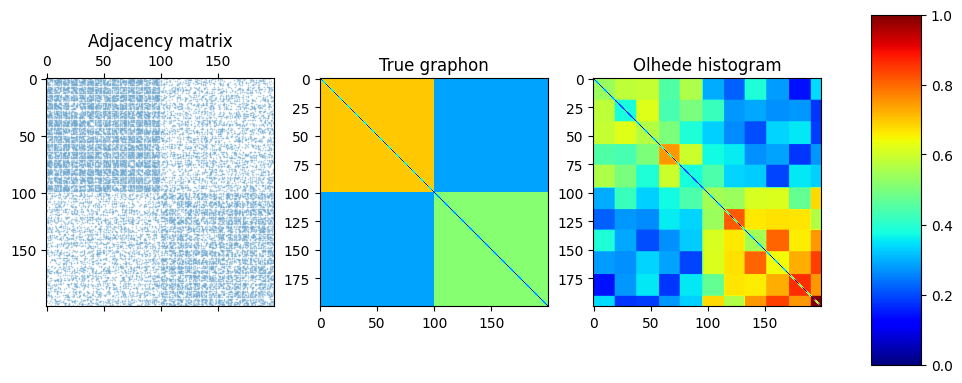

In [59]:
fig, ax = plt.subplots(1, 3, figsize=(10, 5))
fig.subplots_adjust(right=0.9)
cbar_ax = fig.add_axes([0.95, 0.15, 0.05, 0.7])
im1 = ax[1].imshow(graphon.get_edge_probabilities(n,False,True), cmap='jet', vmin=0, vmax=1)
im2 = ax[2].imshow(first_hist_olhede[0].get_edge_probabilities(n,False,True), cmap='jet', vmin=0, vmax=1)
_ = spy(adjacency_matrix, ax=ax[0])
ax[0].set_title("Adjacency matrix")
ax[1].set_title("True graphon")
ax[2].set_title("Olhede histogram")
plt.colorbar(im1, cax=cbar_ax)
plt.colorbar(im2, cax=cbar_ax)
plt.show()

# Smooth NetHist fit 

In [60]:
my_est = SmoothNetHist()
my_est.fit(adjacency_matrix)

In [ ]:
my_est._first_fit_graphon

In [61]:
print("Ratio of parameters:", my_est.get_ratio_par())
print("Number of unique parameters in SmoothNetHist:", len(np.unique(my_est.graphon.get_graphon())))
print("Number of unique parameters in Olhede:", len(np.unique(first_hist_olhede[0].get_graphon())))


Ratio of parameters: 0.12121212121212122
Number of unique parameters in SmoothNetHist: 8
Number of unique parameters in Olhede: 61


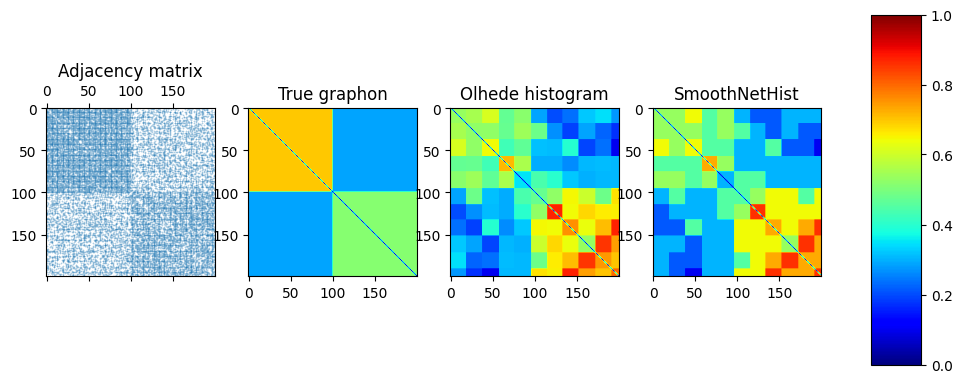

In [63]:
fig, ax = plt.subplots(1, 4, figsize=(10, 5))
fig.subplots_adjust(right=0.9)
cbar_ax = fig.add_axes([0.95, 0.15, 0.05, 0.7])
im1 = ax[1].imshow(graphon.get_edge_probabilities(n,False,True), cmap='jet', vmin=0, vmax=1)
im2 = ax[2].imshow(my_est._first_fit_graphon.get_edge_probabilities(n,False,True), cmap='jet', vmin=0, vmax=1)
im3 = ax[3].imshow(my_est.graphon.get_edge_probabilities(n,False,True), cmap='jet', vmin=0, vmax=1)
_ = spy(adjacency_matrix, ax=ax[0])
ax[0].set_title("Adjacency matrix")
ax[1].set_title("True graphon")
ax[2].set_title("Olhede histogram")
ax[3].set_title("SmoothNetHist")
plt.colorbar(im1, cax=cbar_ax)
plt.colorbar(im2, cax=cbar_ax)
plt.colorbar(im3, cax=cbar_ax)
plt.show()

In [68]:
my_est._first_fit_graphon

In [71]:
norm_olhede_mse = MseProbaEdge(n_nodes=n)(graphon, my_est._first_fit_graphon)
norm_olhede_mae = MaeProbaEdge(n_nodes=n)(graphon, my_est._first_fit_graphon)
norm_olhede_auc = AUCEdge(n_nodes=n)(adjacency_matrix, my_est._first_fit_graphon.get_edge_probabilities(n,False,True))
norm_olhede_auprc = AUPRCEdge(n_nodes=n)(adjacency_matrix, my_est._first_fit_graphon.get_edge_probabilities(n,False,True))

norm_smoothnet_mse = MseProbaEdge(n_nodes=n)(graphon, my_est.graphon)
norm_smoothnet_mae = MaeProbaEdge(n_nodes=n)(graphon, my_est.graphon)
norm_smoothnet_auc = AUCEdge(n_nodes=n)(adjacency_matrix, my_est.graphon.get_edge_probabilities(n,False,True))
norm_smoothnet_auprc = AUPRCEdge(n_nodes=n)(adjacency_matrix, my_est.graphon.get_edge_probabilities(n,False,True))

print("MSE Olhede vs SmoothNetHist:", norm_olhede_mse, norm_smoothnet_mse)
print("MAE Olhede vs SmoothNetHist:", norm_olhede_mae, norm_smoothnet_mae)
print("AUC Olhede vs SmoothNetHist:", norm_olhede_auc, norm_smoothnet_auc)
print("AUPRC Olhede vs SmoothNetHist:", norm_olhede_auprc, norm_smoothnet_auprc)

MSE Olhede vs SmoothNetHist: 0.023805593784530846 0.024534242739544024
MAE Olhede vs SmoothNetHist: 0.11921431508202393 0.12121519647261392
AUC Olhede vs SmoothNetHist: 0.625802535119449 0.6224437129457097
AUPRC Olhede vs SmoothNetHist: 0.5304015260318301 0.5222904762887413
